# Tutorial 1: Getting started

pubmed-stream searches PubMed Central (PMC) and saves the full text of each matching article as one JSON file, with its metadata, reference list and plain text. This tutorial downloads a small search and looks at everything it produced:

1. Download a search and read the summary.
2. See what was saved, and what one article contains.
3. Turn the downloads into a table and chart them.
4. Choose an output format.
5. Re-run a search, which only fetches what is new.

The notebook queries NCBI and takes about a minute. It needs the tutorial extras: `pip install "pubmed-stream[tutorials]"`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import tutorial_utils as tu

tu.setup()   # work in tutorials/workspace/
tu.style()

import pubmed_stream
from pubmed_stream import search_and_download

print("pubmed-stream", pubmed_stream.__version__)

pubmed-stream 0.2.0


## 1. Download a search

`search_and_download` searches PMC, then fetches each article's full-text XML in parallel threads, within NCBI's rate limits. Field tags such as `[Title]` keep a search focused; tutorial 2 covers search design.

**Unavailable** articles are not errors: their publishers do not allow the full text to be downloaded as XML, so they are counted and skipped.

In [2]:
QUERY = '"gut microbiota"[Title] AND frailty[Title/Abstract]'

stats = search_and_download(QUERY, max_results=12)


Found 12 PMC IDs for '"gut microbiota"[Title] AND frailty[Title/Abstract]' (total PubMed results: 66)
Output directory: publications\gut_microbiota_Title_AND_frailty_Title_Abstract



2 articles were not available in PMC full-text


Progress: 12/12 processed (OK:10 | FAIL:2 | SKIP:0)

Download Summary
Keyword:           "gut microbiota"[Title] AND frailty[Title/Abstract]
Total found:       66
Requested:         12
[OK] Successful:   10
[FAIL] Failed:     2
  - Unavailable:   2
  - Errors:        0
[SKIP] Skipped:    0
Duration:          6.2s
Output directory:  publications\gut_microbiota_Title_AND_frailty_Title_Abstract


The summary is also returned as a `DownloadStats` object, for use in code:

In [3]:
print(f"PMC has {stats.total_found} matches; {stats.requested} were requested.")
print(f"Saved {stats.successful}, unavailable {stats.unavailable}, errors {stats.errors}.")
print(f"Success rate {stats.success_rate:.0f}% in {stats.duration_seconds:.1f} s, saved to {stats.output_dir}")

PMC has 66 matches; 12 were requested.
Saved 10, unavailable 2, errors 0.
Success rate 83% in 6.2 s, saved to publications\gut_microbiota_Title_AND_frailty_Title_Abstract


## 2. What was saved

Each search gets a folder named after the query. It holds one `PMC<id>.json` file per article and `query.json`, which records the exact search so tools like the knowledge graph can name it.

In [4]:
folder = stats.output_dir
for path in sorted(folder.iterdir())[:6]:
    print(f"{path.name:22} {path.stat().st_size / 1024:6.1f} KB")
print("...")
print(json.loads((folder / "query.json").read_text(encoding="utf-8")))

PMC12797849.json         41.4 KB
PMC12832458.json         53.8 KB
PMC12888429.json         78.0 KB
PMC12899124.json         62.7 KB
PMC13002377.json         47.1 KB
PMC13346421.json         80.1 KB
...
{'query': '"gut microbiota"[Title] AND frailty[Title/Abstract]', 'retrieved': '2026-10-18T14:19:36'}


One article file has four parts: identifiers, the download date, a `metadata` block, and the plain `text` of the article.

In [5]:
first = sorted(folder.glob("PMC*.json"))[0]
article = json.loads(first.read_text(encoding="utf-8"))
meta = article["metadata"]

def preview(value):
    text = value if isinstance(value, str) else json.dumps(value, ensure_ascii=False)
    return tu.short(text, 90)

pd.DataFrame([(key, preview(value)) for key, value in meta.items()], columns=["metadata field", "value"])

,metadata field,value
0,journal_title,"Journal of Health, Population, and Nutrition"
1,journal_nlm_ta,J Health Popul Nutr
2,journal_iso_abbrev,J Health Popul Nutr
3,journal,"Journal of Health, Population, and Nutrition"
4,pmcid,PMC12797849
5,pmid,41361501
6,doi,10.1186/s41043-025-01184-8
7,linked_discoveries_url,https://linkeddiscoveries.ncbi.nlm.nih.gov/413...
8,title,Association between a dietary index for gut mi...
9,year,2025


`references` lists the cited works that have a PubMed ID or DOI. These become citation links in a knowledge graph. The `text` field has the title, abstract and body, one paragraph per line, ready for search or NLP:

In [6]:
print(f"{len(meta.get('references', []))} references with a PMID or DOI, for example:")
for ref in meta.get("references", [])[:3]:
    print("  ", ref)
print()
print(article["text"][:700], "...")

38 references with a PMID or DOI, for example:
   {'doi': '10.1016/s0140-6736(19)31786-6', 'pmid': '31609228', 'title': 'Frailty: implications for clinical practice and public health', 'year': '2019'}
   {'doi': '10.1016/s2468-2667(18)30091-4', 'pmid': '29908859', 'title': 'Frailty and pre-frailty in middle-aged and older adults and its association with multimorbidity and mortality: a prospective analysis of 493 737 UK biobank participants', 'year': '2018'}
   {'doi': '10.1016/j.ejim.2016.03.007', 'pmid': '27039014', 'title': 'Frailty measurement in research and clinical practice: a review', 'year': '2016'}

Association between a dietary index for gut microbiota and frailty in U.S. adults aged 40 and older: evidence from NHANES 1999–2018
Background
Frailty is an increasing public health concern, and diet is a key modifiable factor in its management. However, it remains unclear whether the dietary index for gut microbiota (DI-GM), which reflects gut-supporting dietary patterns, is assoc

## 3. All downloads as a table

Reading every file into a pandas table makes the corpus easy to sort, filter and chart.

In [7]:
rows = []
for path in sorted(folder.glob("PMC*.json")):
    a = json.loads(path.read_text(encoding="utf-8"))
    m = a["metadata"]
    rows.append({
        "pmcid": a["pmcid"],
        "year": int(m["year"]) if m.get("year", "").isdigit() else None,
        "title": m.get("title", ""),
        "journal": m.get("journal", ""),
        "authors": len(m.get("authors", [])),
        "references": len(m.get("references", [])),
        "words": len(a.get("text", "").split()),
    })
corpus = pd.DataFrame(rows).sort_values("words", ascending=False)
corpus.assign(title=corpus.title.map(lambda t: tu.short(t, 60)))

,pmcid,year,title,journal,authors,references,words
6,PMC13411117,2026,"Gut Microbiota and Ageing: Mechanisms, Age-Rel...",Healthcare,3,58,11085
5,PMC13346421,2026,Gut microbiota associates with frailty in olde...,Nature Communications,13,54,9492
2,PMC12888429,2026,Exploring gut microbiota mechanisms in frailty...,Nutrition & Metabolism,11,68,8607
7,PMC13468338,2026,Gut Microbiota-Targeted Nutrition for Healthy ...,Nutrients,11,288,7815
1,PMC12832458,2026,Correlation between the gut microbiota composi...,Frontiers in Nutrition,5,47,5906
3,PMC12899124,2026,Composition of the Gut Microbiota in Older Adu...,Nutrients,10,76,5823
9,PMC13512376,2026,How Gut Microbiota Influence Healthy Aging: Ov...,Geriatrics,5,34,5159
4,PMC13002377,2026,Dietary index for gut microbiota is inversely ...,Frontiers in Nutrition,5,40,5093
0,PMC12797849,2025,Association between a dietary index for gut mi...,"Journal of Health, Population, and Nutrition",6,38,4324
8,PMC13472779,2026,Commentary: Correlation between the gut microb...,Frontiers in Nutrition,4,11,921


Full-text length and reference lists vary a lot between articles. A short text often means a brief report or an article whose body is mostly tables and figures.

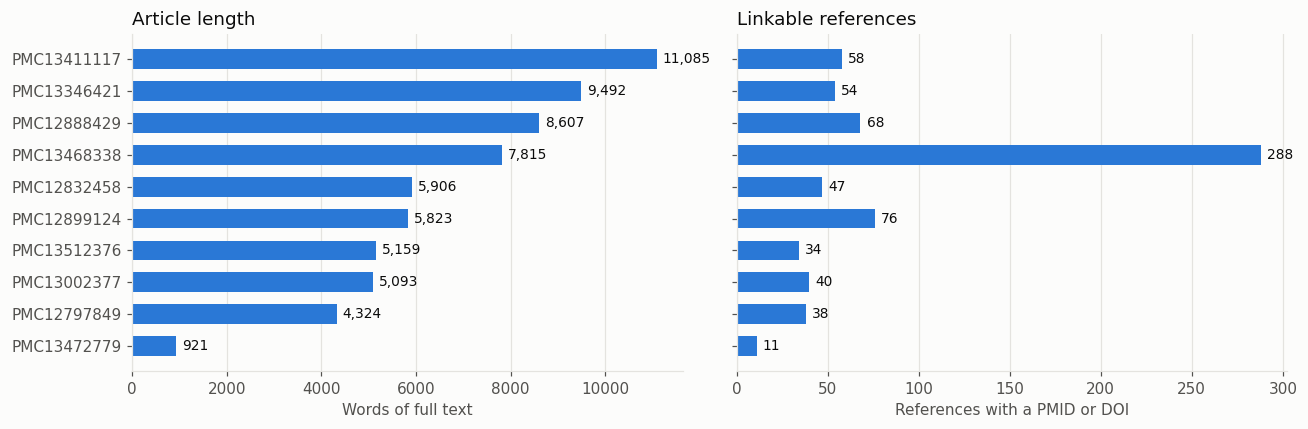

In [8]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
labels = corpus.pmcid
bars = left.barh(labels, corpus.words, color=tu.BLUE, height=0.62)
tu.bar_labels(left, bars, fmt="{:,.0f}", horizontal=True)
tu.gridlines(left, "x")
left.invert_yaxis()
left.set_xlabel("Words of full text")
left.set_title("Article length")

bars = right.barh(labels, corpus.references, color=tu.BLUE, height=0.62)
tu.bar_labels(right, bars, horizontal=True, zero=True)
tu.gridlines(right, "x")
right.set_xlabel("References with a PMID or DOI")
right.set_title("Linkable references")
plt.tight_layout()
plt.show()

## 4. Choose an output format

Every format saves one JSON file with the same metadata. They differ in what else they keep:

| `fmt` | Adds | Use it for |
|---|---|---|
| `"text"` (default) | `text`: plain text, one paragraph per line | Reading, search, embeddings, most NLP |
| `"xml"` | `xml`: the raw JATS XML | Section-level parsing, tables, figures |
| `"both"` | `text` and `xml` | Keeping every option open |

`include_text=False` drops the `text` field to save space. Here are the same three articles in each format:

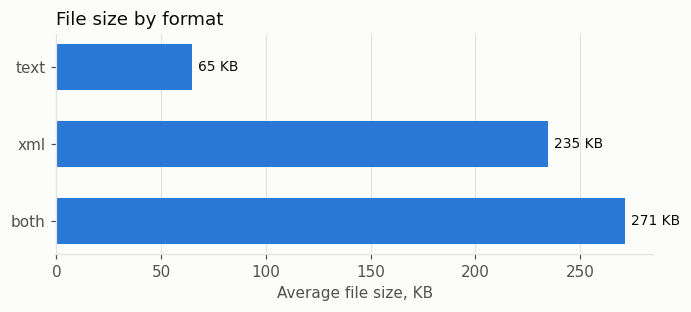

In [9]:
import contextlib
import io

sizes = {}
for fmt in ["text", "xml", "both"]:
    with contextlib.redirect_stdout(io.StringIO()):   # hide the three download reports
        s = search_and_download(QUERY, max_results=3, fmt=fmt, output_dir=f"formats/{fmt}")
    files = list(s.output_dir.glob("PMC*.json"))
    sizes[fmt] = sum(f.stat().st_size for f in files) / len(files) / 1024

fig, ax = plt.subplots(figsize=(7, 2.6))
bars = ax.barh(list(sizes)[::-1], list(sizes.values())[::-1], color=tu.BLUE, height=0.6)
tu.bar_labels(ax, bars, fmt="{:,.0f} KB", horizontal=True)
tu.gridlines(ax, "x")
ax.set_xlabel("Average file size, KB")
ax.set_title("File size by format")
plt.show()

## 5. Re-run a search

Files that already exist are skipped, so running a search again only downloads new articles. This is how a study stays current, and how an interrupted download resumes.

In [10]:
again = search_and_download(QUERY, max_results=12)
print(f"New: {again.successful}, already downloaded: {again.skipped}")


Found 12 PMC IDs for '"gut microbiota"[Title] AND frailty[Title/Abstract]' (total PubMed results: 66)
Output directory: publications\gut_microbiota_Title_AND_frailty_Title_Abstract



2 articles were not available in PMC full-text


Progress: 12/12 processed (OK:0 | FAIL:2 | SKIP:10)

Download Summary
Keyword:           "gut microbiota"[Title] AND frailty[Title/Abstract]
Total found:       66
Requested:         12
[OK] Successful:   0
[FAIL] Failed:     2
  - Unavailable:   2
  - Errors:        0
[SKIP] Skipped:    10
Duration:          2.9s
Output directory:  publications\gut_microbiota_Title_AND_frailty_Title_Abstract
New: 0, already downloaded: 10


## The same from the command line

```bash
pubmed-stream download '"gut microbiota"[Title] AND frailty[Title/Abstract]' --max-results 12
pubmed-stream download '"gut microbiota"[Title] AND frailty[Title/Abstract]' --format both -o formats
```

The command exits with 0 when articles were saved or already present, 1 when the search found nothing, and 2 when every download failed.

**Next:** tutorial 2 shows how to design searches that find the right papers.